In [ ]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress

# 地理空间处理库
from shapely.geometry import Point
import geopandas as gpd

# 并行处理库
from multiprocessing import Pool, cpu_count

# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
from cartopy import crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.path as mpath
import matplotlib.ticker as mticker
from matplotlib.colors import Normalize
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import warnings
import matplotlib.patches as mpatches
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            if i > trend_select and i < (len_amp - trend_select - min_len):
                continue
            # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            if (j - i - min_len) > trend_select:
                continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]


    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio
    else:
        return diff, sign, p_diff

def process_trend_diff(args):
    """
    并行处理趋势差异计算的函数。
    """
    data, time, min_line, trend_select = args
    return cal_trend_diff(data, time, min_line, trend_select)

def cal_area_grid(lat, lon, radius=6371000):
    lat_rad = np.radians(lat)
    lat_diff = np.diff(lat_rad) / 2  # 使用中间差值
    
    area = np.zeros((len(lat), len(lon)))
    
    lat_area_factors = radius ** 2 * np.abs(
        np.sin(lat_rad[:-1] + lat_diff) - np.sin(lat_rad[:-1] - lat_diff)
    )

    lon_diff = np.abs(np.radians(lon[1] - lon[0]))

    area[:-1, :] = lat_area_factors[:, np.newaxis] * lon_diff
    area[-1, :] = area[-2, :] 
    area[:, -1] = area[:, -2] 
    
    return area

def cal_trend_rolling(data, time, min_len):
    """
    计算数据的滚动趋势

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势

    Returns:
    trend_map : 二维数组，包含滚动趋势
    time_map : 二维数组，包含对应的时间映射
    """
    len_amp = len(data)
    # trend_amp [[p, b], rolling]    time_map [start_time, end_time]
    trend_map = np.full((len_amp - min_len, 2), np.nan)
    time_map = np.full((len_amp - min_len, 2), np.nan)

    for i in range(len_amp - min_len):
        amp_now = data[i:i + min_len]
        trend_result = trend_window(amp_now, min_len, cal_type=0).squeeze()
        trend_map[i] = trend_result
        time_map[i] = [time[i], time[i + min_len]]

    return trend_map, time_map

In [1]:
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-3-GC-exp-amp/'
files = os.listdir(folder)
model_dict = {}
exp_list = ['control', 'land', 'transport', 'ocean+fossil']
min_len = 20
trend_select = 7
lat_lim = 50
count_diff = np.sum(np.arange(1, trend_select + 1))

for file in files:
    model = file.split('.')[0]
    with xr.open_dataset(os.path.join(folder, file)) as ds:
        exp_list_temp = ds.exp_list.values[[0, 1, -1]]
        amp_grid_temp = ds.amp_grid.values
        amp_region_temp = ds.amp_region.values
        time = ds.time.values
        lon = ds.lon.values
        lat = ds.lat.values
        amp_grid = [amp_grid_temp[0], amp_grid_temp[1], amp_grid_temp[-1]]
        amp_region = [amp_region_temp[0], amp_region_temp[1], amp_region_temp[-1]]

        if 'ocean' in ds.exp_list.values:
            amp_grid.append(amp_grid_temp[2:4].sum(axis=0))
            amp_region.append(amp_region_temp[2:4].sum(axis=0))
            exp_list_temp = np.append(exp_list_temp, 'ocean+fossil')

        amp_grid = np.array(amp_grid)
        amp_region = np.array(amp_region)
        model_dict[model] = {
            'exp_list': exp_list_temp,
            'amp_grid': amp_grid,
            'amp_region': amp_region,
            'time': time,
            'lon': lon,
            'lat': lat
        }

of_mean_grid = []
of_mean_region = []
for model in ['CAMS', 'Jena']:
    of_mean_grid.append(model_dict[model]['amp_grid'][-1])
    of_mean_region.append(model_dict[model]['amp_region'][-1])
of_mean_grid = np.nanmean(of_mean_grid, axis=0)
of_mean_region = np.nanmean(of_mean_region, axis=0)

if 'Multi-model' in model_dict:
    of_mean_expanded = np.expand_dims(of_mean_grid, axis=0)
    of_mean_region_expanded = np.expand_dims(of_mean_region, axis=0)
    
    model_dict['Multi-model']['amp_grid'] = np.append(
        model_dict['Multi-model']['amp_grid'], 
        of_mean_expanded, 
        axis=0
    )
    model_dict['Multi-model']['amp_region'] = np.append(
        model_dict['Multi-model']['amp_region'], 
        of_mean_region_expanded,
        axis=0
    )
    model_dict['Multi-model']['exp_list'] = np.append(
        model_dict['Multi-model']['exp_list'], 
        'ocean+fossil'
    )

# ---------------- 开始并行计算 ----------------
tasks = []
tasks_index = []

for model, info in model_dict.items():
    amp_grid = info['amp_grid']  # (n_exp, n_time, n_lat, n_lon)
    time = info['time']
    lat = info['lat']
    
    n_exp, n_time, n_lat, n_lon = amp_grid.shape
    
    for e in range(n_exp):
        for i in range(n_lat):
            if lat[i] < lat_lim:
                continue
            for j in range(n_lon):
                tasks.append((amp_grid[e, :, i, j], time, min_len, trend_select))
                tasks_index.append((model, e, i, j))

print(f"Total tasks to process: {len(tasks)}")
with Pool(processes=cpu_count()-2) as pool:
    results = pool.map(process_trend_diff, tasks)

# 初使化并分配数组
for model, info in model_dict.items():
    n_exp, n_time, n_lat, n_lon = info['amp_grid'].shape
    
    info['diff_grid']   = np.full((n_exp, count_diff, n_lat, n_lon), np.nan)
    info['sign_grid']   = np.full((n_exp, n_lat, n_lon), np.nan)
    info['p_diff_grid'] = np.full((n_exp, n_lat, n_lon), np.nan)

for idx, res in enumerate(results):
    model, e, i, j = tasks_index[idx]
    diff, sign, p_diff = res
    
    model_dict[model]['diff_grid'][e, :, i, j] = diff
    model_dict[model]['sign_grid'][e, i, j] = sign
    model_dict[model]['p_diff_grid'][e, i, j] = p_diff

print("Trend difference calculation completed.")


NameError: name 'os' is not defined

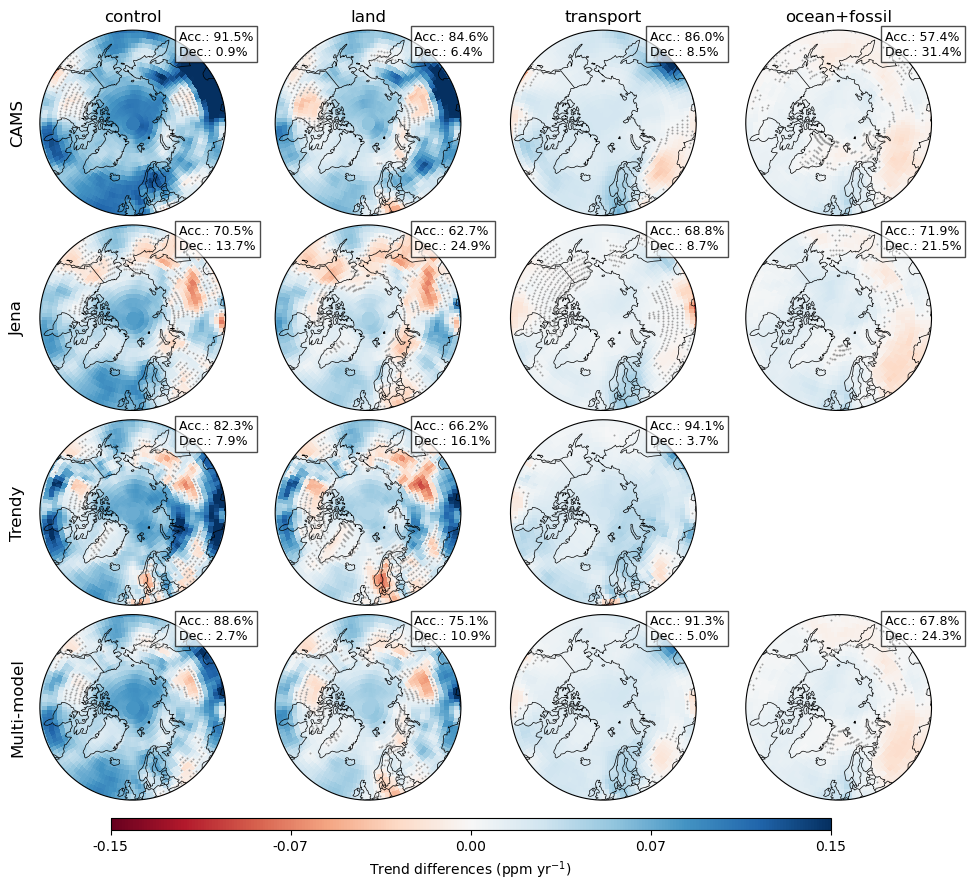

In [ ]:
# 画图
fig = plt.figure(figsize=(12, 10))
gs = gridspec.GridSpec(4, 4, width_ratios=[1]*4, height_ratios=[1]*4, wspace=0.05, hspace=0.05)
axs = np.empty((4, 4), dtype=object)
alpha = 0.7
vmax_value = 0.15

for n_m, (model, info) in enumerate(model_dict.items()):
    exp_list_temp = info['exp_list']
    lon = info['lon']
    lat = info['lat']
    index = np.where(lat == lat_lim)[0][0]
    lat = lat[index:]

    for n_e, exp in enumerate(exp_list_temp):
        ax = axs[n_m, n_e]
        ax = fig.add_subplot(gs[n_m, n_e], projection=ccrs.NorthPolarStereo(central_longitude=0))
        ax.set_extent([-180, 180, lat_lim, 90], crs=ccrs.PlateCarree())
        ax.coastlines(resolution='110m', linewidth=0.5)
        ax.add_feature(cfeature.BORDERS, linewidth=0.5)
        theta = np.linspace(0, 2*np.pi, 240)
        r = 0.5
        verts = np.vstack([0.5 + r*np.cos(theta), 0.5 + r*np.sin(theta)]).T
        circle_path = mpath.Path(verts)
        ax.set_boundary(circle_path, transform=ax.transAxes)
        axs[n_m, n_e] = ax

        trend_data = info['diff_grid'][n_e, :, index:].mean(axis=0)
        sign_start = info['sign_grid'][n_e, index:]
        p_value = info['p_diff_grid'][n_e, index:]

        mask = np.where(np.logical_or(p_value > 0.1, sign_start < 0), 1, np.nan)  # 显著性掩码
        all_mask = mask.copy()
        area = cal_area_grid(lat, lon)
        
        # 标注加速/减速百分比
        acc_percent = 0
        dec_percent = 0
        total_count = 0
        for i in range(trend_data.shape[0]):
            for j in range(trend_data.shape[1]):
                total_count += area[i, j]
                if np.logical_and(p_value[i, j] <= 0.1, sign_start[i, j] > 0):
                    if trend_data[i, j] >= 0:
                        acc_percent += area[i, j]
                    elif trend_data[i, j] < 0:
                        dec_percent += area[i, j]
        total_percent = acc_percent + dec_percent
        acc_percent = acc_percent / total_count * 100
        dec_percent = dec_percent / total_count * 100
        ax.text(0.75, 1, f'Acc.: {acc_percent:.1f}%\nDec.: {dec_percent:.1f}%', 
                transform=ax.transAxes, ha='left', va='top', fontsize=9,
                bbox=dict(boxstyle='square', facecolor='white', alpha=alpha, 
                            edgecolor='black', linestyle='-'))

        # 绘图
        im = ax.pcolormesh(lon, lat, trend_data, cmap='RdBu', vmin=-vmax_value, vmax=vmax_value, 
                            transform=ccrs.PlateCarree())

        # 标注不显著区域
        mask_points = np.isfinite(all_mask) & (all_mask == 1)
        if np.any(mask_points):
            lon2d, lat2d = np.meshgrid(lon, lat)
            ax.scatter(lon2d[mask_points], lat2d[mask_points],
                        s=2, c='gray', marker='o', alpha=alpha,
                        transform=ccrs.PlateCarree(), zorder=5, linewidths=0, rasterized=True)

# 添加 colorbar
cbar_ax = fig.add_axes([0.2, 0.08, 0.6, 0.012])  # [left, bottom, width, height]
norm = Normalize(vmin=-vmax_value, vmax=vmax_value)
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap='RdBu'), cax=cbar_ax, orientation='horizontal')
cbar.set_label('Trend differences (ppm yr$^{-1}$)', fontsize=10)
cbar.set_ticks(np.linspace(-vmax_value, vmax_value, 5))
cbar.set_ticklabels([f'{tick:.2f}' for tick in np.linspace(-vmax_value, vmax_value, 5)])

for i in range(4):
    ax = axs[0, i]
    ax.text(0.5, 1.03, exp_list[i], transform=ax.transAxes, ha='center', va='bottom', fontsize=12)
    ax = axs[i, 0]
    ax.text(-0.08, 0.5, list(model_dict.keys())[i], transform=ax.transAxes, ha='right', va='center', fontsize=12, rotation=90)


fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-3-GC-diffmap.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)

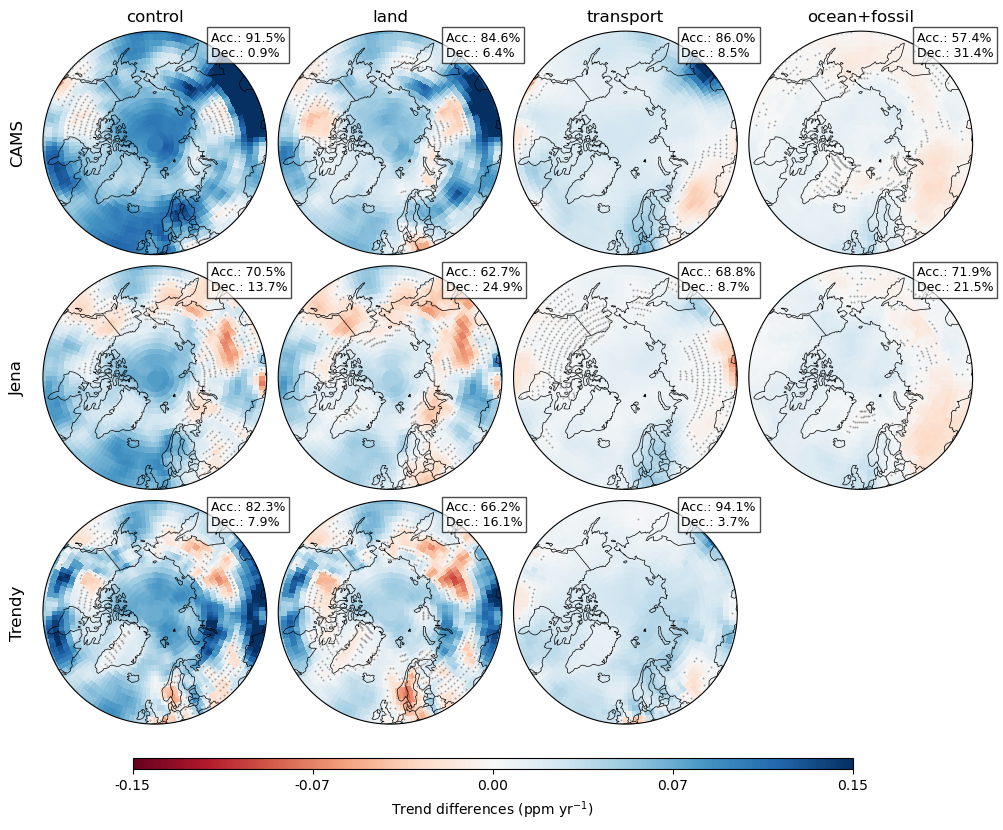

In [ ]:
# ============================================================
# Figure 1: CAMS, Jena, Trendy → 3×4 grid
# ============================================================
fig = plt.figure(figsize=(12, 9))
gs = gridspec.GridSpec(3, 4, width_ratios=[1]*4, height_ratios=[1]*3, wspace=0.05, hspace=0.05)
axs = np.empty((3, 4), dtype=object)
alpha = 0.7
vmax_value = 0.15

model_keys = list(model_dict.keys())  # ['CAMS', 'Jena', 'Trendy', 'Multi-model']

for n_m in range(3):
    model = model_keys[n_m]
    info = model_dict[model]
    exp_list_temp = info['exp_list']
    lon = info['lon']
    lat = info['lat']
    index = np.where(lat == lat_lim)[0][0]
    lat = lat[index:]

    for n_e, exp in enumerate(exp_list_temp):
        ax = fig.add_subplot(gs[n_m, n_e], projection=ccrs.NorthPolarStereo(central_longitude=0))
        ax.set_extent([-180, 180, lat_lim, 90], crs=ccrs.PlateCarree())
        ax.coastlines(resolution='110m', linewidth=0.5)
        ax.add_feature(cfeature.BORDERS, linewidth=0.5)
        theta = np.linspace(0, 2*np.pi, 240)
        r = 0.5
        verts = np.vstack([0.5 + r*np.cos(theta), 0.5 + r*np.sin(theta)]).T
        circle_path = mpath.Path(verts)
        ax.set_boundary(circle_path, transform=ax.transAxes)
        axs[n_m, n_e] = ax

        trend_data = info['diff_grid'][n_e, :, index:].mean(axis=0)
        sign_start = info['sign_grid'][n_e, index:]
        p_value = info['p_diff_grid'][n_e, index:]

        mask = np.where(np.logical_or(p_value > 0.1, sign_start < 0), 1, np.nan)
        all_mask = mask.copy()
        area = cal_area_grid(lat, lon)

        # 标注加速/减速百分比
        acc_percent = 0
        dec_percent = 0
        total_count = 0
        for i in range(trend_data.shape[0]):
            for j in range(trend_data.shape[1]):
                total_count += area[i, j]
                if np.logical_and(p_value[i, j] <= 0.1, sign_start[i, j] > 0):
                    if trend_data[i, j] >= 0:
                        acc_percent += area[i, j]
                    elif trend_data[i, j] < 0:
                        dec_percent += area[i, j]
        acc_percent = acc_percent / total_count * 100
        dec_percent = dec_percent / total_count * 100
        ax.text(0.75, 1, f'Acc.: {acc_percent:.1f}%\nDec.: {dec_percent:.1f}%',
                transform=ax.transAxes, ha='left', va='top', fontsize=9,
                bbox=dict(boxstyle='square', facecolor='white', alpha=alpha,
                          edgecolor='black', linestyle='-'))

        im = ax.pcolormesh(lon, lat, trend_data, cmap='RdBu', vmin=-vmax_value, vmax=vmax_value,
                           transform=ccrs.PlateCarree())

        mask_points = np.isfinite(all_mask) & (all_mask == 1)
        if np.any(mask_points):
            lon2d, lat2d = np.meshgrid(lon, lat)
            ax.scatter(lon2d[mask_points], lat2d[mask_points],
                       s=2, c='gray', marker='o', alpha=alpha,
                       transform=ccrs.PlateCarree(), zorder=5, linewidths=0, rasterized=True)

# 添加 colorbar
cbar_ax = fig.add_axes([0.2, 0.06, 0.6, 0.012])
norm = Normalize(vmin=-vmax_value, vmax=vmax_value)
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap='RdBu'), cax=cbar_ax, orientation='horizontal')
cbar.set_label('Trend differences (ppm yr$^{-1}$)', fontsize=10)
cbar.set_ticks(np.linspace(-vmax_value, vmax_value, 5))
cbar.set_ticklabels([f'{tick:.2f}' for tick in np.linspace(-vmax_value, vmax_value, 5)])

# 列标签
for i in range(4):
    ax = axs[0, i]
    ax.text(0.5, 1.03, exp_list[i], transform=ax.transAxes, ha='center', va='bottom', fontsize=12)

# 行标签
for i in range(3):
    ax = axs[i, 0]
    ax.text(-0.08, 0.5, model_keys[i], transform=ax.transAxes, ha='right', va='center', fontsize=12, rotation=90)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-3-GC-diffmap.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)

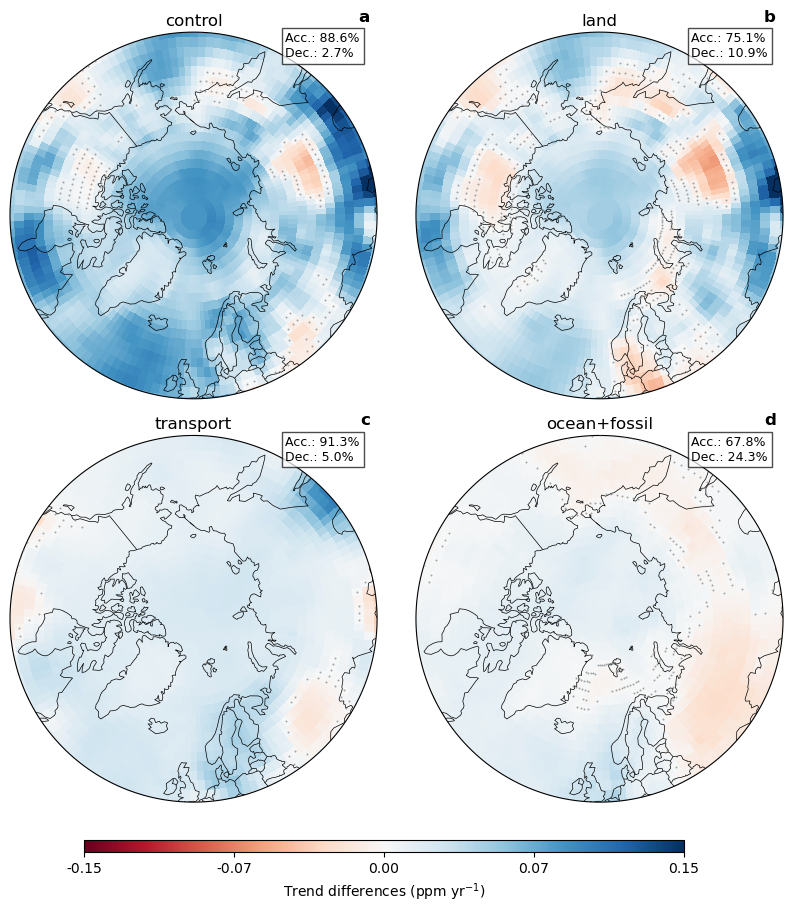

In [ ]:
# ============================================================
# Figure 2: Multi-model → 2×2 grid
# ============================================================
fig = plt.figure(figsize=(10, 10))
gs = gridspec.GridSpec(2, 2, width_ratios=[1]*2, height_ratios=[1]*2, wspace=0.1, hspace=0.1)
axs_mm = np.empty((2, 2), dtype=object)
alpha = 0.7
vmax_value = 0.15

info = model_dict['Multi-model']
exp_list_temp = info['exp_list']
lon = info['lon']
lat = info['lat']
index = np.where(lat == lat_lim)[0][0]
lat = lat[index:]

for n_e, exp in enumerate(exp_list_temp):
    row = n_e // 2
    col = n_e % 2
    ax = fig.add_subplot(gs[row, col], projection=ccrs.NorthPolarStereo(central_longitude=0))
    ax.set_extent([-180, 180, lat_lim, 90], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='110m', linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    theta = np.linspace(0, 2*np.pi, 240)
    r = 0.5
    verts = np.vstack([0.5 + r*np.cos(theta), 0.5 + r*np.sin(theta)]).T
    circle_path = mpath.Path(verts)
    ax.set_boundary(circle_path, transform=ax.transAxes)
    axs_mm[row, col] = ax

    trend_data = info['diff_grid'][n_e, :, index:].mean(axis=0)
    sign_start = info['sign_grid'][n_e, index:]
    p_value = info['p_diff_grid'][n_e, index:]

    mask = np.where(np.logical_or(p_value > 0.1, sign_start < 0), 1, np.nan)
    all_mask = mask.copy()
    area = cal_area_grid(lat, lon)

    acc_percent = 0
    dec_percent = 0
    total_count = 0
    for i in range(trend_data.shape[0]):
        for j in range(trend_data.shape[1]):
            total_count += area[i, j]
            if np.logical_and(p_value[i, j] <= 0.1, sign_start[i, j] > 0):
                if trend_data[i, j] >= 0:
                    acc_percent += area[i, j]
                elif trend_data[i, j] < 0:
                    dec_percent += area[i, j]
    acc_percent = acc_percent / total_count * 100
    dec_percent = dec_percent / total_count * 100
    ax.text(0.75, 1, f'Acc.: {acc_percent:.1f}%\nDec.: {dec_percent:.1f}%',
            transform=ax.transAxes, ha='left', va='top', fontsize=9,
            bbox=dict(boxstyle='square', facecolor='white', alpha=alpha,
                      edgecolor='black', linestyle='-'))

    im = ax.pcolormesh(lon, lat, trend_data, cmap='RdBu', vmin=-vmax_value, vmax=vmax_value,
                       transform=ccrs.PlateCarree())

    mask_points = np.isfinite(all_mask) & (all_mask == 1)
    if np.any(mask_points):
        lon2d, lat2d = np.meshgrid(lon, lat)
        ax.scatter(lon2d[mask_points], lat2d[mask_points],
                   s=2, c='gray', marker='o', alpha=alpha,
                   transform=ccrs.PlateCarree(), zorder=5, linewidths=0, rasterized=True)

# 添加 colorbar
cbar_ax = fig.add_axes([0.2, 0.06, 0.6, 0.012])
norm = Normalize(vmin=-vmax_value, vmax=vmax_value)
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap='RdBu'), cax=cbar_ax, orientation='horizontal')
cbar.set_label('Trend differences (ppm yr$^{-1}$)', fontsize=10)
cbar.set_ticks(np.linspace(-vmax_value, vmax_value, 5))
cbar.set_ticklabels([f'{tick:.2f}' for tick in np.linspace(-vmax_value, vmax_value, 5)])

exp_list_temp = ['control', 'land', 'transport', 'ocean+fossil']
for i in range(2):
    for j in range(2):
        index = i * 2 + j
        ax = axs_mm[i, j]
        ax.text(0.5, 1.01, exp_list_temp[index], transform=ax.transAxes, ha='center', va='bottom', fontsize=12)

letters = ['A', 'B', 'C', 'D']
for i in range(2):
    for j in range(2):
        index = i * 2 + j
        ax = axs_mm[i, j]
        ax.text(0.98, 1.02, letters[index], transform=ax.transAxes, ha='right', va='bottom', fontsize=12, fontweight='bold')

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-3-GC-diffmap-Ensemble.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)

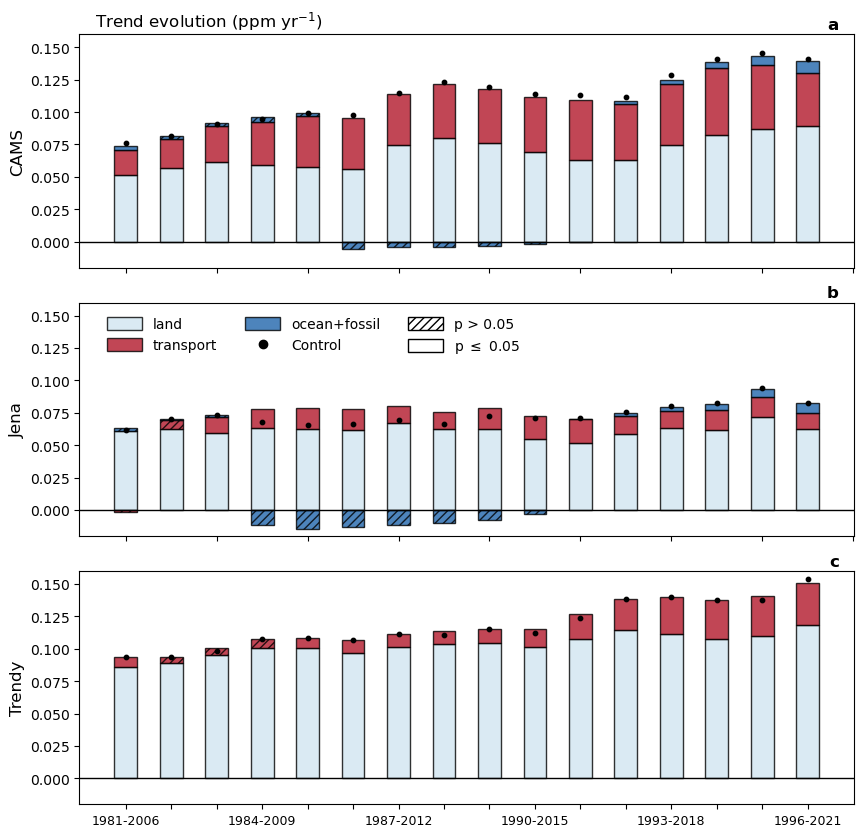

In [ ]:
# Trend evolution
n_models = 3
idx = [1, 5, 6, 8, 13, 15]
idx_temp = [2, 7, 9, 10, 14]
gs = gridspec.GridSpec(n_models, 1, width_ratios=[1], height_ratios=[1]*n_models, hspace=0.15)
fig = plt.figure(figsize=(10, 10))  
axs = np.empty((n_models), dtype=object)
for i in range(n_models):
    axs[i] = fig.add_subplot(gs[i])

for n_m, model in enumerate(['CAMS', 'Jena', 'Trendy']):
    info = model_dict[model]
    ax = axs[n_m]
    amp_region = info['amp_region']  # (n_exp, n_time)
    time = info['time']
    trend_roll = []
    for n_e in range(amp_region.shape[0]):
        trend_temp, time_roll = cal_trend_rolling(amp_region[n_e], time, 25)
        trend_roll.append(trend_temp)
    trend_roll = np.array(trend_roll)
    if model == 'Trendy':
        trend_roll = trend_roll[:, 1:]
        time_roll = time_roll[1:] 
        
    exp_list = info['exp_list']
    x_data = time_roll[:, 1]
    n_points = len(x_data)

    # 分别记录正负值的堆叠底线
    bottom_pos = np.zeros(n_points)
    bottom_neg = np.zeros(n_points)

    colors = ['#d1e5f0', '#b2182b', '#2166ac',  '#ef8a62']

    for n_e, exp in enumerate(exp_list[1:]):
        y_data = trend_roll[n_e+1, :, 1]
        p_data = trend_roll[n_e+1, :, 0] 
        
        # 根据 y 值的正负选择对应的底线
        bottom = np.where(y_data > 0, bottom_pos, bottom_neg)
        
        bars = ax.bar(x_data, y_data, bottom=bottom, label=exp, 
                      color=colors[n_e % len(colors)], width=0.5,
                      edgecolor='black', linewidth=1, alpha=0.8)

        for idx, rect in enumerate(bars):
            if p_data[idx] > 0.1:
                rect.set_hatch('////')

        # 更新底线
        bottom_pos += np.maximum(y_data, 0)
        bottom_neg += np.minimum(y_data, 0)
    ax.scatter(x_data, trend_roll[0, :, 1], color='black', s=10, zorder=5)  # 添加散点以突出显示 x 轴
    ax.axhline(0, color='black', linewidth=1)

letters = ['a', 'b', 'c']
for i in range(3):
    ax = axs[i]
    ax.set_ylim(-0.02, 0.16)
    ax.set_xticklabels([])
    ax.text(0.98, 1.01, letters[i], transform=ax.transAxes, ha='right', va='bottom', 
            fontsize=12, fontweight='bold')
    ax.text(-0.07, 0.5, list(model_dict.keys())[i], transform=ax.transAxes, ha='right', va='center', 
            fontsize=12, rotation=90)

exp_list = ['control', 'land', 'transport', 'ocean+fossil']
custom_lines = [
    mpatches.Patch(facecolor=colors[i], edgecolor='black', linewidth=1, alpha=0.8) 
    for i in range(len(exp_list)-1)
]
# 添加 Control 的散点标识
custom_lines.append(Line2D([0], [0], marker='o', color='black', markerfacecolor='black', markersize=6, lw=0))

# 分别添加表示“不显著(带斜线)”和“显著(空白)”的图例框
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', hatch='////', linewidth=1))
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', linewidth=1))

labels_legend = ['land', 'transport', 'ocean+fossil', 'Control', 'p > 0.05', 'p $\leq$ 0.05']

# 将 ncols 改为 3 以适应 6 个图例项的排版
axs[1].legend(custom_lines, labels_legend, bbox_to_anchor=(0.02, 0.99), 
          loc='upper left', frameon=False, fontsize=10,
          handlelength=2.5, handleheight=1., ncols=3)
axs[0].text(0.02, 1.01, 'Trend evolution (ppm yr$^{-1}$)', fontsize=12,
        va='bottom', ha='left', transform=axs[0].transAxes)

xticks_label = []
for i in range(n_points):
    start_year = int(time_roll[i, 0])
    end_year = int(time_roll[i, 1])
    xticks_label.append(f'{start_year}-{end_year}')

axs[-1].set_xticks(x_data)  
display_labels = [label if i % 3 == 0 else "" for i, label in enumerate(xticks_label)]
axs[-1].set_xticklabels(display_labels, rotation=0, fontsize=9) 

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-3-GC-trend-evo.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)